# 01 — População dos municípios de SC (D31)

Perguntas: quais municípios concentram a população, como ela variou entre os Censos de 2010 e 2022
e como se comportam as estimativas anuais.

Os dados vêm só das views do schema `gold`, lidas como `bed_readonly` pelas funções de `brasil_em_dados.analise`. Os valores aparecem como estão na GOLD (R\$, habitantes, %): nenhuma conversão de unidade (regra 11); os eixos só abreviam o texto dos rótulos.

Regras que valem para a leitura:
- **Censo e estimativa nunca na mesma linha** (regra 2): a variação oficial é Censo 2010 × Censo 2022;
  a estimativa entra como série à parte.
- **A estimativa tem três bases** (regra 12): até 2012, 2013–2017 e desde 2018. Não se compara
  valor de bases diferentes sem aviso.
- **2012 tem dupla contagem** (regra 13): a soma estadual de 2012 exclui Pescaria Brava e
  Balneário Rincão.
- **Ausência não é zero** (regra 5): os dois municípios instalados em 2013 não têm Censo 2010.

In [1]:
%matplotlib inline

from brasil_em_dados.analise import calculos, consultas
from brasil_em_dados.analise import graficos as g
from brasil_em_dados.db import engine_readonly

engine = engine_readonly()  # bed_readonly; cada consulta roda numa transação READ ONLY
g.configurar_tabelas()  # números das tabelas no padrão brasileiro

## 1. Concentração da população (Censo 2022)

Os 10 maiores municípios somam 40,6% da população de SC.
Metade da população vive em 17 dos 295 municípios.
Os 10 maiores estão em 6 das 7 regiões intermediárias.


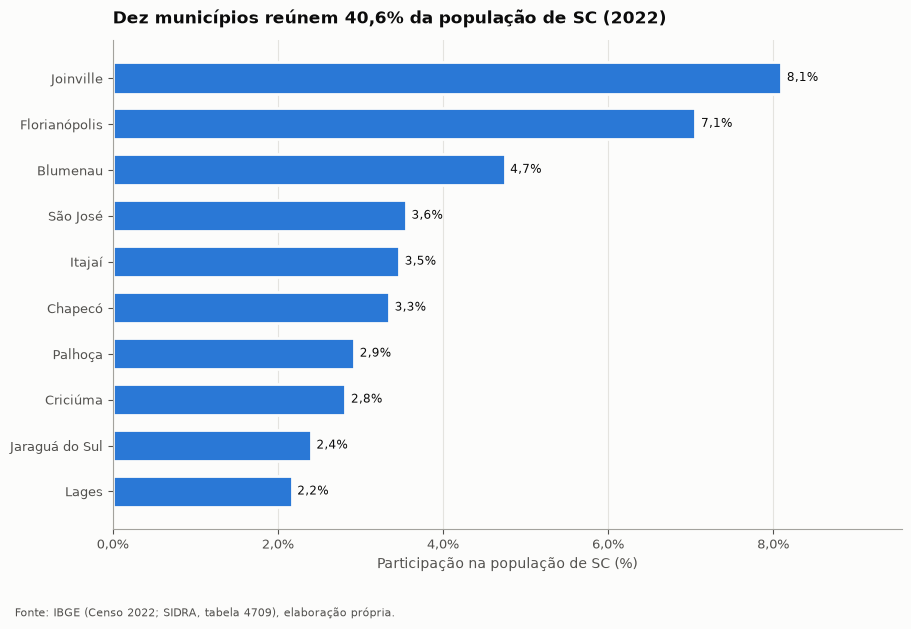

In [2]:
part_pop = consultas.participacao(engine, "pop_censo", 2022)
top_pop = calculos.top_n(part_pop, "valor")
acumulada = calculos.participacao_acumulada(part_pop)
metade = calculos.quantos_somam(part_pop)
print(f"Os 10 maiores municípios somam {g.formatar_percentual(acumulada)} da população de SC.")
print(f"Metade da população vive em {metade} dos 295 municípios.")
regioes_top = calculos.anexar(top_pop, consultas.painel(engine, 2022), ["nome_regiao_intermediaria"])
print(f"Os 10 maiores estão em {regioes_top['nome_regiao_intermediaria'].nunique()} das 7 regiões intermediárias.")

g.barras_horizontais(
    top_pop["nome_municipio"], top_pop["participacao_percentual"],
    titulo=f"Dez municípios reúnem {g.formatar_percentual(acumulada)} da população de SC (2022)",
    rotulo_eixo="Participação na população de SC (%)",
    fonte=g.FONTE_CENSO_2022, formatar=g.formatar_percentual)

In [3]:
top_pop[["nome_municipio", "valor", "participacao_percentual"]].rename(columns={
    "nome_municipio": "Município", "valor": "População (Censo 2022)",
    "participacao_percentual": "Participação (%)"})

,Município,População (Censo 2022),Participação (%)
0,Joinville,"616.317,00","8,10"
1,Florianópolis,"537.211,00","7,06"
2,Blumenau,"361.261,00","4,75"
3,São José,"270.299,00","3,55"
4,Itajaí,"264.054,00","3,47"
5,Chapecó,"254.785,00","3,35"
6,Palhoça,"222.598,00","2,92"
7,Criciúma,"214.493,00","2,82"
8,Jaraguá do Sul,"182.660,00","2,40"
9,Lages,"164.981,00","2,17"


**Leitura.** Joinville e Florianópolis lideram, com 8,1% e 7,1% da população. Os dez maiores somam
40,6% do estado, metade da população está em 17 municípios, e os dez maiores ficam em 6 das 7 regiões
intermediárias. O projeto não tem dados de outros estados (escopo, D01), então não compara essa
concentração com a de outras UFs.

## 2. Censo 2010 × Censo 2022

In [4]:
censo_sc = consultas.agregado(engine, "estado", "pop_censo")
variacao_sc = calculos.variacao_entre_anos(censo_sc, 2010, 2022)
var = consultas.variacao_censo(engine)
resumo = calculos.resumo(var["variacao_percentual"])
print(f"SC: {g.formatar_habitantes(variacao_sc['valor_inicial'][0])} (2010) → "
      f"{g.formatar_habitantes(variacao_sc['valor_final'][0])} (2022), "
      f"{g.formatar_percentual(variacao_sc['variacao_percentual'][0])}")
print(f"Municípios comparáveis: {resumo.n}; perderam população: {resumo.negativos}; "
      f"mediana da variação: {g.formatar_percentual(resumo.mediana)}")
print("Sem variação (instalados em 2013):",
      ", ".join(var.loc[var["variacao_percentual"].isna(), "nome_municipio"]))

SC: 6,25 mi (2010) → 7,61 mi (2022), 21,8%
Municípios comparáveis: 293; perderam população: 70; mediana da variação: 6,8%
Sem variação (instalados em 2013): Pescaria Brava, Balneário Rincão


Posição em população (2022) dos 5 maiores ganhos: Florianópolis (2º), Joinville (1º), Palhoça (7º), Itajaí (5º), Chapecó (6º)


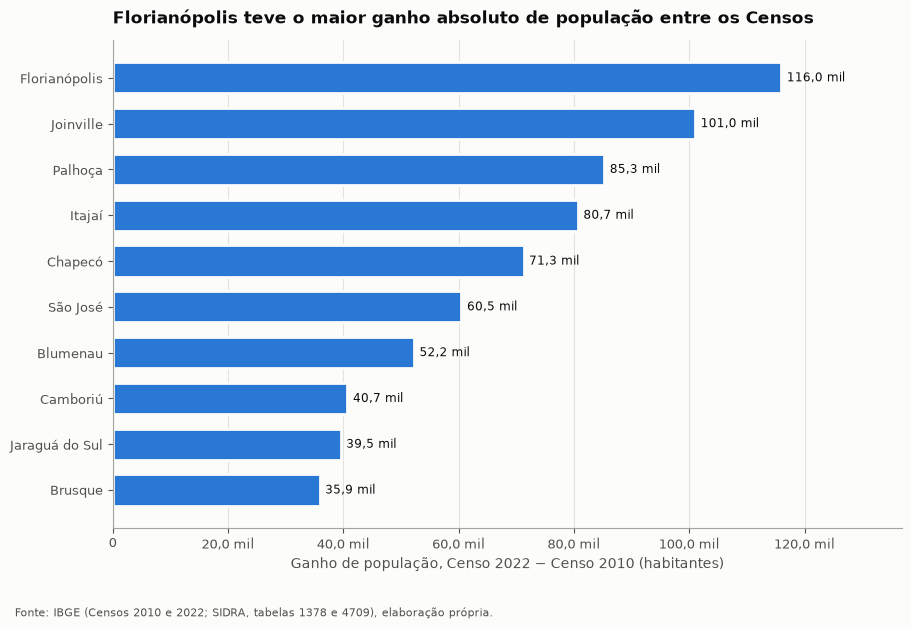

In [5]:
ganhos = calculos.top_n(var, "variacao_absoluta")
part_pop_2022 = consultas.participacao(engine, "pop_censo", 2022)
posicao_2022 = {cod: i + 1 for i, cod in enumerate(part_pop_2022["cod_municipio"])}
print("Posição em população (2022) dos 5 maiores ganhos:",
      ", ".join(f"{n} ({posicao_2022[c]}º)" for n, c in zip(ganhos["nome_municipio"][:5], ganhos["cod_municipio"][:5])))
g.barras_horizontais(
    ganhos["nome_municipio"], ganhos["variacao_absoluta"],
    titulo=f"{ganhos['nome_municipio'][0]} teve o maior ganho absoluto de população entre os Censos",
    rotulo_eixo="Ganho de população, Censo 2022 − Censo 2010 (habitantes)",
    fonte=g.FONTE_CENSOS, formatar=g.formatar_habitantes)

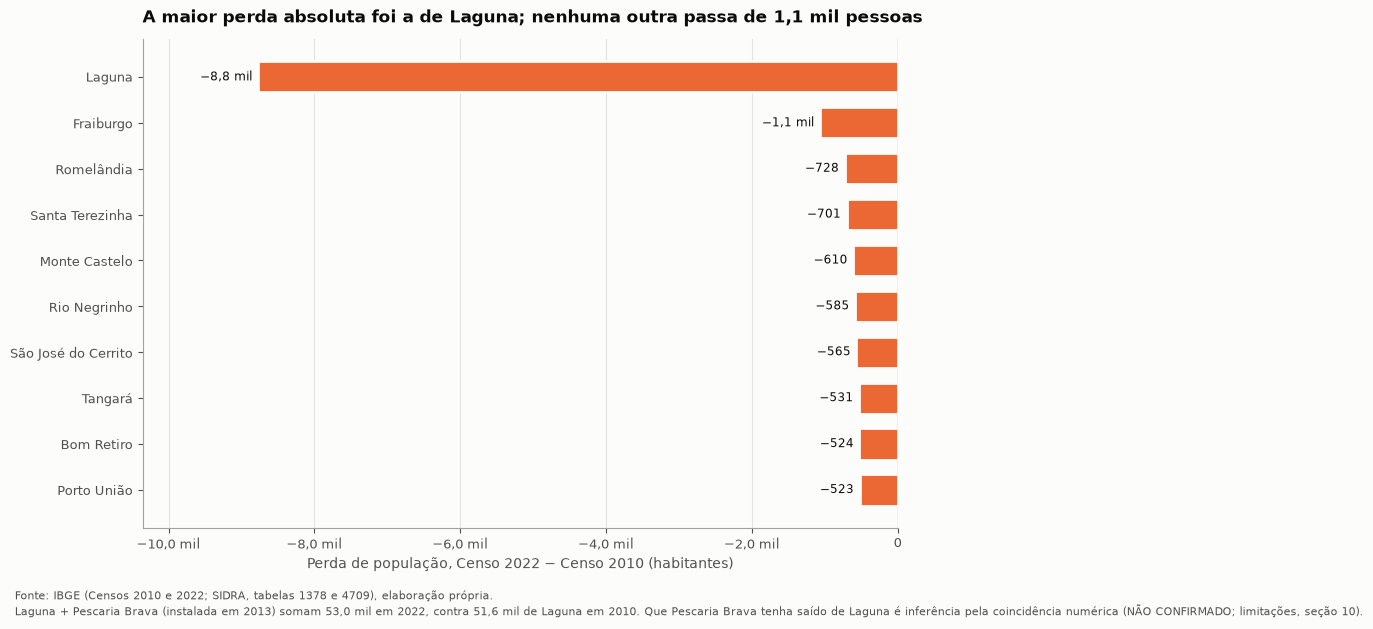

In [6]:
perdas = calculos.top_n(var, "variacao_absoluta", maiores=False)
por_codigo = var.set_index("cod_municipio")  # regra 1: código IBGE é a chave, nunca o nome
laguna_2010 = por_codigo.loc["4209409", "pop_censo_2010"]
laguna_e_pescaria_2022 = por_codigo.loc[["4209409", "4212650"], "pop_censo_2022"].sum()
g.barras_horizontais(
    perdas["nome_municipio"], perdas["variacao_absoluta"],
    titulo=f"A maior perda absoluta foi a de {perdas['nome_municipio'][0]}; nenhuma outra passa de "
           f"{g.formatar_habitantes(-perdas['variacao_absoluta'][1])} pessoas",
    rotulo_eixo="Perda de população, Censo 2022 − Censo 2010 (habitantes)",
    fonte=g.FONTE_CENSOS, formatar=g.formatar_habitantes,
    cores=[g.PALETA["contraste"]] * len(perdas),
    nota=f"Laguna + Pescaria Brava (instalada em 2013) somam {g.formatar_habitantes(laguna_e_pescaria_2022)} "
         f"em 2022, contra {g.formatar_habitantes(laguna_2010)} de Laguna em 2010. Que Pescaria Brava "
         "tenha saído de Laguna é inferência pela coincidência numérica (NÃO CONFIRMADO; limitações, seção 10).")

Municípios que perderam população, por região intermediária:
nome_regiao_intermediaria
Chapecó          36
Lages            14
Blumenau          6
Joinville         6
Caçador           6
Criciúma          1
Florianópolis     1
Os 10 que mais cresceram tinham de 4,7 mil a 31,0 mil habitantes em 2010.
População mediana em 2010: 4,7 mil nos que perderam população; 7,5 mil em todos.


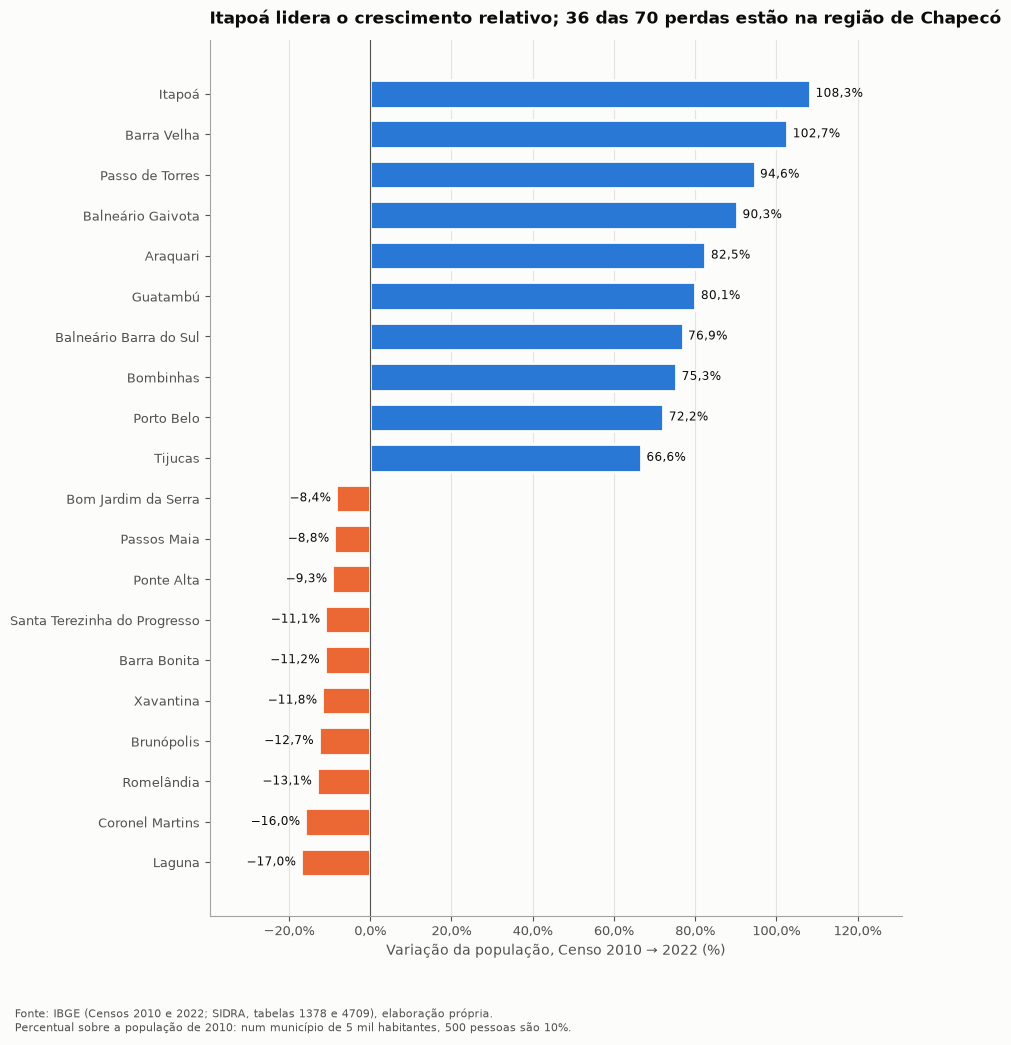

In [7]:
ext_pct = calculos.extremos(var, "variacao_percentual")
perdas_por_regiao = var.loc[var["variacao_percentual"] < 0, "nome_regiao_intermediaria"].value_counts()
print("Municípios que perderam população, por região intermediária:")
print(perdas_por_regiao.to_string())
mais_cresceram = calculos.top_n(var, "variacao_percentual")
print(f"Os 10 que mais cresceram tinham de {g.formatar_habitantes(mais_cresceram['pop_censo_2010'].min())} "
      f"a {g.formatar_habitantes(mais_cresceram['pop_censo_2010'].max())} habitantes em 2010.")
print(f"População mediana em 2010: {g.formatar_habitantes(var.loc[var['variacao_percentual'] < 0, 'pop_censo_2010'].median())} "
      f"nos que perderam população; {g.formatar_habitantes(var['pop_censo_2010'].median())} em todos.")
g.barras_horizontais(
    ext_pct["nome_municipio"], ext_pct["variacao_percentual"],
    titulo=f"{ext_pct['nome_municipio'][0]} lidera o crescimento relativo; "
           f"{perdas_por_regiao.iloc[0]} das {int(perdas_por_regiao.sum())} perdas estão na região de {perdas_por_regiao.index[0]}",
    rotulo_eixo="Variação da população, Censo 2010 → 2022 (%)",
    fonte=g.FONTE_CENSOS, formatar=g.formatar_percentual,
    cores=g.cores_por_sinal(ext_pct["variacao_percentual"]),
    nota="Percentual sobre a população de 2010: num município de 5 mil habitantes, 500 pessoas são 10%.")

**Leitura.** Em números absolutos, os cinco maiores ganhos (Florianópolis, Joinville, Palhoça, Itajaí
e Chapecó) são de municípios que estão entre os 7 mais populosos de 2022. Em percentual, os dez que
mais cresceram tinham de 4,7 mil a 31,0 mil habitantes em 2010; Itapoá e Barra Velha mais que
dobraram. As perdas não passam de 1,1 mil pessoas, exceto em Laguna, e se concentram nas regiões
intermediárias de Chapecó (36 dos 70) e de Lages (14). A população mediana de quem perdeu era de
4,7 mil em 2010, contra 7,5 mil no conjunto dos municípios.

Laguna (−17%) é um caso à parte. Somada a Pescaria Brava, instalada em 2013, tem 52.975 habitantes em
2022, contra 51.562 de Laguna em 2010. Isso sugere que a queda vem do desmembramento, mas a origem de
Pescaria Brava foi associada a Laguna só pela coincidência numérica: **NÃO CONFIRMADO** (limitações,
seções 9 e 10).

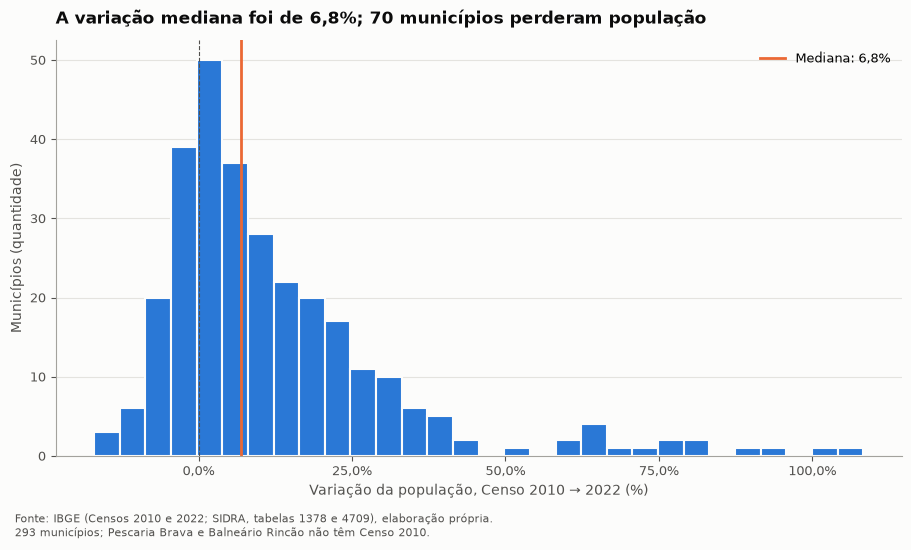

In [8]:
g.histograma(
    var["variacao_percentual"],
    titulo=f"A variação mediana foi de {g.formatar_percentual(resumo.mediana)}; "
           f"{resumo.negativos} municípios perderam população",
    rotulo_eixo="Variação da população, Censo 2010 → 2022 (%)",
    fonte=g.FONTE_CENSOS, formatar=g.formatar_percentual, referencia_zero=True,
    nota="293 municípios; Pescaria Brava e Balneário Rincão não têm Censo 2010.")

Região intermediária de Laguna, Içara, Pescaria Brava e Balneário Rincão: Criciúma


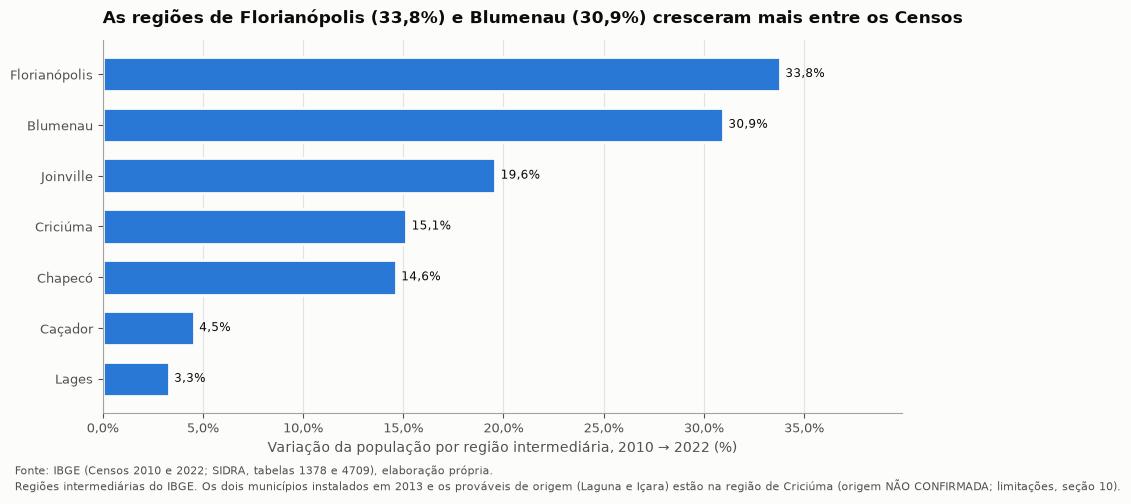

In [9]:
reg_pop = consultas.agregado(engine, "regiao_intermediaria", "pop_censo")
var_reg = calculos.variacao_entre_anos(reg_pop, 2010, 2022)
envolvidos = por_codigo.loc[["4209409", "4207007", "4212650", "4220000"]]  # Laguna, Içara e os dois novos
print("Região intermediária de Laguna, Içara, Pescaria Brava e Balneário Rincão:",
      ", ".join(sorted(set(envolvidos["nome_regiao_intermediaria"]))))
g.barras_horizontais(
    var_reg["nome_regiao"], var_reg["variacao_percentual"],
    titulo=f"As regiões de {var_reg['nome_regiao'][0]} "
           f"({g.formatar_percentual(var_reg['variacao_percentual'][0])}) e {var_reg['nome_regiao'][1]} "
           f"({g.formatar_percentual(var_reg['variacao_percentual'][1])}) cresceram mais entre os Censos",
    rotulo_eixo="Variação da população por região intermediária, 2010 → 2022 (%)",
    fonte=g.FONTE_CENSOS, formatar=g.formatar_percentual,
    nota="Regiões intermediárias do IBGE. Os dois municípios instalados em 2013 e os prováveis de origem "
         "(Laguna e Içara) estão na região de Criciúma (origem NÃO CONFIRMADA; limitações, seção 10).")

**Leitura.** As regiões intermediárias de Florianópolis (+33,8%) e Blumenau (+30,9%) cresceram mais;
as de Caçador (+4,5%) e Lages (+3,3%), menos. Pescaria Brava, Balneário Rincão, Laguna e Içara ficam
todos na região de Criciúma. Por isso, o total regional de 2010 e o de 2022 cobrem o mesmo território
se a população dos municípios novos estava contada em Laguna e Içara em 2010, o que é **NÃO
CONFIRMADO** (limitações, seção 10). As outras seis regiões não são afetadas.

## 3. Estimativas anuais 2011–2021

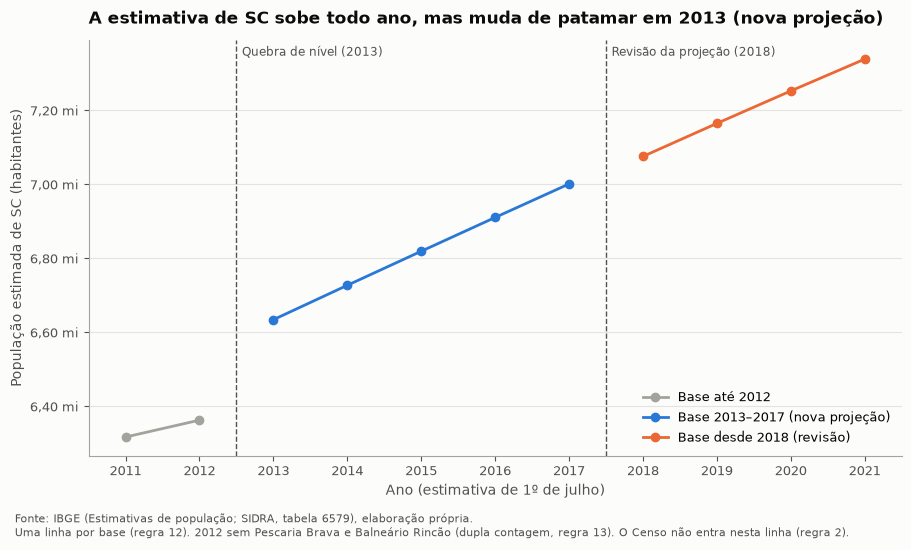

In [10]:
estimativa_sc = consultas.agregado(engine, "estado", "pop_estimada")
g.serie_estimativa_por_base(
    calculos.segmentos_por_base(estimativa_sc),
    titulo="A estimativa de SC sobe todo ano, mas muda de patamar em 2013 (nova projeção)",
    rotulo_eixo="População estimada de SC (habitantes)",
    fonte=g.FONTE_ESTIMATIVA, formatar=g.formatar_habitantes,
    nota="Uma linha por base (regra 12). 2012 sem Pescaria Brava e Balneário Rincão (dupla contagem, "
         "regra 13). O Censo não entra nesta linha (regra 2).")

In [11]:
for base, serie in calculos.segmentos_por_base(estimativa_sc):
    taxas = calculos.variacao_sequencial(serie)["variacao_percentual"].dropna()
    if not taxas.empty:
        print(f"{base}: de {g.formatar_percentual(taxas.min(), 2)} a {g.formatar_percentual(taxas.max(), 2)} ao ano")
estimativa_sc[["ano", "base_estimativa", "valor", "municipios_excluidos", "aviso"]]

ate_2012: de 0,72% a 0,72% ao ano
2013_2017: de 1,31% a 1,40% ao ano
desde_2018: de 1,19% a 1,26% ao ano


,ano,base_estimativa,valor,municipios_excluidos,aviso
0,2011,ate_2012,"6.317.054,00",0,NaN
1,2012,ate_2012,"6.362.734,00",2,pop_estimada 2012 sem 4212650 e 4220000: dupla...
2,2013,2013_2017,"6.634.254,00",0,NaN
3,2014,2013_2017,"6.727.148,00",0,NaN
4,2015,2013_2017,"6.819.190,00",0,NaN
5,2016,2013_2017,"6.910.553,00",0,NaN
6,2017,2013_2017,"7.001.161,00",0,NaN
7,2018,desde_2018,"7.075.494,00",0,NaN
8,2019,desde_2018,"7.164.788,00",0,NaN
9,2020,desde_2018,"7.252.502,00",0,NaN


**Leitura.** Dentro de cada base a partir de 2013, a estimativa cresce de 1,19% a 1,40% ao ano. As
taxas não incluem os pares entre bases (2012→2013 e 2017→2018), que não são comparáveis. O degrau entre
2012 e 2013 é mudança de método (nova projeção por UF), não crescimento: por isso as linhas não se
ligam e a variação 2012→2013 não é calculada. A revisão de 2018 não mostra salto em SC, mas o IBGE
declara comparáveis só os anos de 2013 a 2017. A estimativa não substitui os Censos: a variação
oficial do projeto é Censo 2010 × Censo 2022 (limitações, seções 1 a 3).